In [53]:
import os, glob
import numpy as np
import pandas as pd
import keras
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, recall_score

In [54]:
files = glob.glob("data/**/*.csv", recursive=True)
df = pd.concat((pd.read_csv(f, encoding="latin1") for f in files), ignore_index=True)
df.columns = df.columns.str.strip()
print(df.shape)

(2830743, 79)


In [55]:
df["Label"] = df["Label"].str.replace(r"[^\x20-\x7E]+", "-", regex=True)
df = df.replace([np.inf, -np.inf], np.nan).dropna().drop_duplicates()
df["is_attack"] = (df["Label"] != "BENIGN").astype(int)
print(df.shape)
print(df["is_attack"].value_counts())

(2520798, 80)
is_attack
0    2095057
1     425741
Name: count, dtype: int64


In [56]:
df = pd.read_parquet("data/clean.parquet")

In [57]:
features = df.columns.drop(["Label", "is_attack"])
X = df[features].astype("float32")
y = df["is_attack"].astype("float32")
labels = df["Label"]

X_train, X_tmp, y_train, y_tmp, l_train, l_tmp = train_test_split(
    X, y, labels, test_size=0.30, stratify=labels, random_state=42)
X_val, X_test, y_val, y_test, l_val, l_test = train_test_split(
    X_tmp, y_tmp, l_tmp, test_size=0.50, stratify=l_tmp, random_state=42)

print(X_train.shape, X_val.shape, X_test.shape)

(1764558, 78) (378120, 78) (378120, 78)


In [58]:
norm = keras.layers.Normalization()
norm.adapt(X_train.to_numpy())

def prep(X):
    return np.clip(norm(X.to_numpy()).numpy(), -10, 10).astype("float32")

Xn_train, Xn_val, Xn_test = prep(X_train), prep(X_val), prep(X_test)
yv = y_val.to_numpy().astype(int)
yt = y_test.to_numpy().astype(int)
b = (yv == 0)
n = Xn_train.shape[1]

In [59]:
def build_clf():
    m = keras.Sequential([
        keras.Input(shape=(n,)),
        keras.layers.Dense(128, activation="relu"),
        keras.layers.Dropout(0.2),
        keras.layers.Dense(64, activation="relu"),
        keras.layers.Dropout(0.2),
        keras.layers.Dense(1, activation="sigmoid"),
    ])
    m.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="binary_crossentropy",
              metrics=[keras.metrics.AUC(name="auc")])
    return m

In [60]:
cnt = l_train.value_counts()
w = np.clip((cnt.max() / cnt) ** 0.5, 1, 30)
sw = l_train.map(w).to_numpy().astype("float32")

clf2 = build_clf()
clf2.fit(Xn_train, y_train.to_numpy(), sample_weight=sw,
         validation_data=(Xn_val, yv), epochs=15, batch_size=2048,
         callbacks=[keras.callbacks.EarlyStopping(
             monitor="val_auc", mode="max", patience=3,
             restore_best_weights=True)])

Epoch 1/15
862/862 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - auc: 0.9904 - loss: 0.2550 - val_auc: 0.9958 - val_loss: 0.1021
Epoch 2/15
862/862 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - auc: 0.9958 - loss: 0.1562 - val_auc: 0.9975 - val_loss: 0.0718
Epoch 3/15
862/862 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - auc: 0.9968 - loss: 0.1331 - val_auc: 0.9977 - val_loss: 0.0702
Epoch 4/15
862/862 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - auc: 0.9972 - loss: 0.1215 - val_auc: 0.9978 - val_loss: 0.0616
Epoch 5/15
862/862 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - auc: 0.9974 - loss: 0.1154 - val_auc: 0.9980 - val_loss: 0.0665
Epoch 6/15
862/862 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - auc: 0.9976 - loss: 0.1115 - val_auc: 0.9981 - val_loss: 0.0640
Epoch 7/15
862/862 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - auc: 0.9978 - loss: 0.1063 - val_auc: 0.9982 - val_loss: 0.0569
Epoch 8/15
862/862 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - auc: 0.9979 - loss: 0.1029 - val_auc: 0.9986 - val_loss: 0.0647
Epoch 9/15
862/862 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - au

In [61]:
clf2 = keras.models.load_model("models/classifier_weighted.keras")
thr_w = float(np.load("models/clf_threshold.npy"))
print("threshold:", thr_w)

threshold: 0.8707506060600281


In [62]:
p_val = clf2.predict(Xn_val, batch_size=8192, verbose=0).ravel()
pred = p_val > thr_w
print("ROC-AUC:", roc_auc_score(yv, p_val))
print("recall:", pred[yv == 1].mean())
print("FPR:", pred[b].mean())

ROC-AUC: 0.9996049078239988
recall: 0.9840434694101251
FPR: 0.005002243372504845


In [63]:
res = (pd.DataFrame({"label": l_val.to_numpy(), "detected": pred})
       .groupby("label")["detected"].mean().round(3)
       .to_frame().join(l_val.value_counts().rename("n")))
print(res.sort_values("detected"))

                            detected       n
label                                       
BENIGN                         0.005  314259
Heartbleed                     0.500       2
Infiltration                   0.600       5
Bot                            0.623     292
Web Attack - Brute Force       0.638     221
Web Attack - XSS               0.878      98
SSH-Patator                    0.959     483
PortScan                       0.981   13604
DoS Hulk                       0.985   25927
DoS GoldenEye                  0.985    1543
DoS slowloris                  0.989     808
FTP-Patator                    0.990     889
DoS Slowhttptest               0.992     784
DDoS                           0.995   19202
Web Attack - Sql Injection     1.000       3


C:\Users\mo\anaconda3\envs\tf\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
PermutationExplainer explainer: 101it [00:33,  2.68it/s]                         


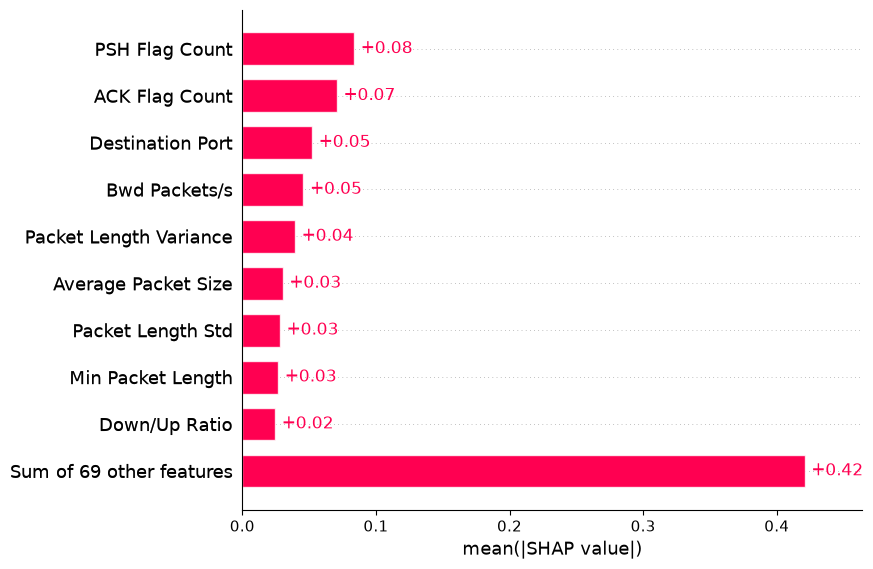

In [64]:
import shap

def f(X):
    return clf2.predict(X, batch_size=4096, verbose=0).ravel()

rng = np.random.default_rng(42)
bg = Xn_val[rng.choice(len(Xn_val), 100, replace=False)]
Xs = Xn_val[rng.choice(len(Xn_val), 100, replace=False)]

explainer = shap.Explainer(f, bg, feature_names=list(features))
sv = explainer(Xs)

shap.plots.bar(sv, max_display=10)

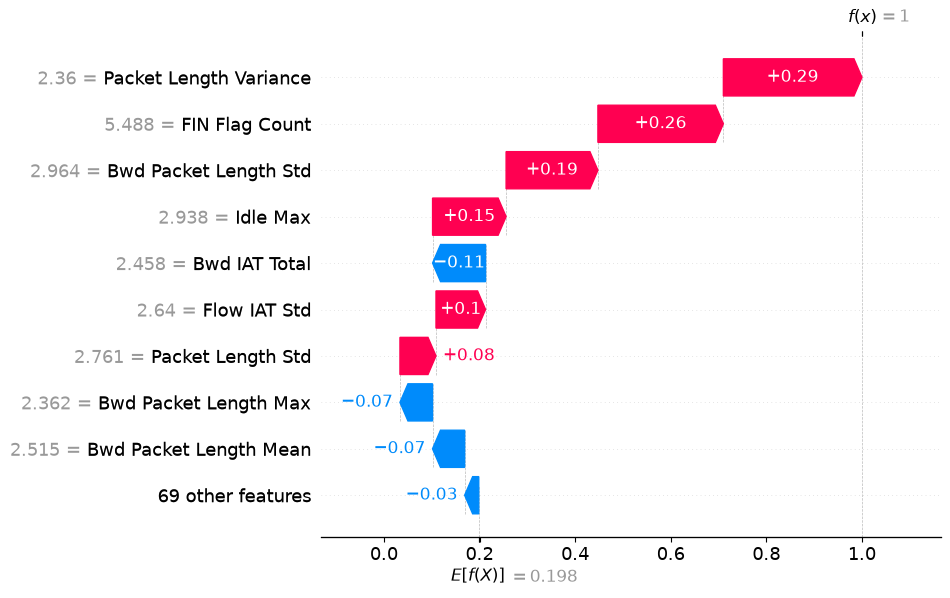

In [65]:
shap.plots.waterfall(sv[0])

In [66]:
np.save("models/shap_background.npy", bg)

In [68]:
mean = np.load("models/norm_mean.npy")
std = np.maximum(np.sqrt(np.load("models/norm_var.npy")), 1e-7)
chk = np.clip((X_test.to_numpy()[:2000] - mean) / std, -10, 10)
print("max diff:", np.abs(chk - Xn_test[:2000]).max())

rng = np.random.default_rng(7)
idx = list(rng.choice(len(X_test), 1500, replace=False))
lt = l_test.to_numpy()
for lab in np.unique(lt[lt != "BENIGN"]):
    pos = np.where(lt == lab)[0]
    idx += list(rng.choice(pos, min(15, len(pos)), replace=False))
idx = rng.permutation(np.unique(idx))

sample = X_test.iloc[idx].copy()
sample["Label"] = lt[idx]
sample.reset_index(drop=True).to_parquet("data/test_sample.parquet")
print(sample.shape)

max diff: 0.0
(1675, 79)
